# 02 — Fine-tuning do GmNet-S3

Treina o GmNet-S3 a partir dos pesos ImageNet-1K (`gmnet_s3.npy`, verificados em 2026-11-23)
no dataset `cerrado_df_v1`, com a configuração `configs/experiments/gmnet_s3_ft.yaml`.

**Antes**: rode o `00_setup_colab.ipynb` no mesmo ambiente (código, Drive e cópia do dataset
para `/content/cache`). Use um ambiente com **GPU**.

- Checkpoints: `<drive_root>/checkpoints/<experimento>/seed_<n>/` (`last.pt` a cada época;
  se o Colab desconectar, rodar de novo retoma de onde parou).
- Resultados: `<drive_root>/results/<experimento>/seed_<n>/` (histórico, métricas, predições,
  metadados da execução). Uma semente já concluída não é treinada de novo.
- O checkpoint é escolhido pelo macro-F1 por foto na **validação**; o **teste** é avaliado
  uma única vez, no final.
- Resultados para o artigo: só no modo `git`, sem alterações não commitadas.

In [12]:
CONFIG = "configs/experiments/gmnet_s3_ft.yaml"
RUN_TESTS = True  # roda a suíte de testes (incluindo os de PyTorch) antes de treinar

## 1. Ambiente

In [13]:
import importlib
import sys
from pathlib import Path

import torch
import yaml

REPO_DIR = Path("/content/ProjetoFinalRNAP_UnB2026")
assert REPO_DIR.exists(), "Rode antes o 00_setup_colab.ipynb neste ambiente."

# O kernel em execução não lê o .pth da instalação editável (ver notebook 00).
SRC_DIR = str(REPO_DIR / "src")
if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)
importlib.invalidate_caches()

from cerrado_flora.utils import run_metadata

paths = yaml.safe_load((REPO_DIR / "configs/paths.yaml").read_text())
cfg = yaml.safe_load((REPO_DIR / CONFIG).read_text())
pretrained_cfg = yaml.safe_load((REPO_DIR / "configs/pretrained.yaml").read_text())

drive_root = Path(paths["drive_root"])
assert drive_root.exists(), "Google Drive não montado (seção 1 do notebook 00)."
images_root = Path(paths["local_cache"]) / cfg["dataset"]["name"]
assert (images_root / "images").exists(), "Dataset ausente: rode a seção 5 do notebook 00."
manifest = REPO_DIR / cfg["dataset"]["manifest"]

meta = run_metadata.collect(REPO_DIR)
print("commit:", meta["git_commit"], "| alterações não commitadas:", meta["git_dirty"])
if meta["git_commit"] is None or meta["git_dirty"]:
    print("AVISO: sem commit limpo; estes resultados não devem entrar no artigo (modo git).")
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NENHUMA")
assert torch.cuda.is_available(), "Selecione um ambiente com GPU."

commit: 20d66f92f2497182ad1bb5c998bf6f3b16bfb898 | alterações não commitadas: False
GPU: Tesla T4


## 2. Testes

In [14]:
import subprocess

if RUN_TESTS:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pytest"], check=True)
    # -rfEs: resumo com falhas (f), erros (E) e testes pulados (s);
    # --tb=short: traceback curto de cada falha. Saída completa, sem cortes.
    r = subprocess.run([sys.executable, "-m", "pytest", "-q", "-rfEs", "--tb=short", "tests"],
                       cwd=REPO_DIR, capture_output=True, text=True)
    print(r.stdout)
    if r.stderr:
        print(r.stderr)
    assert r.returncode == 0, "testes falharam (ver 'short test summary info' acima)"

.............................                                            [100%]
29 passed in 17.06s



## 3. Pesos pré-treinados

In [15]:
from cerrado_flora.models.factory import verify_checkpoint

wcfg = pretrained_cfg[cfg["model"]["pretrained"]]
weights = drive_root / paths["drive_subdirs"]["pretrained"] / wcfg["file"]
verify_checkpoint(weights, wcfg["sha256"])
print("pesos verificados:", weights)

pesos verificados: /content/drive/MyDrive/ProjetoFinalRNAP_UnB2026/pretrained/gmnet_s3.npy


## 4. Treino e avaliação

In [16]:
from cerrado_flora.training.train import run_experiment

exp = cfg["name"]
results = {}
for seed in cfg["seeds"]:
    results[seed] = run_experiment(
        cfg, seed, manifest, images_root, weights,
        ckpt_dir=drive_root / paths["drive_subdirs"]["checkpoints"] / exp / f"seed_{seed}",
        results_dir=drive_root / paths["drive_subdirs"]["results"] / exp / f"seed_{seed}",
    )

semente 2026 já concluída: /content/drive/MyDrive/ProjetoFinalRNAP_UnB2026/results/gmnet_s3_ft/seed_2026/metrics.json


/content/ProjetoFinalRNAP_UnB2026/src/cerrado_flora/training/train.py:153: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


época 1/50  loss 3.353  val top1 0.188  val macro-F1 0.169  (38s)
época 2/50  loss 2.837  val top1 0.482  val macro-F1 0.473  (37s)
época 3/50  loss 1.879  val top1 0.670  val macro-F1 0.693  (40s)
época 4/50  loss 1.340  val top1 0.714  val macro-F1 0.739  (41s)
época 5/50  loss 1.110  val top1 0.745  val macro-F1 0.766  (40s)
época 6/50  loss 1.007  val top1 0.753  val macro-F1 0.771  (40s)
época 7/50  loss 0.915  val top1 0.766  val macro-F1 0.782  (40s)
época 8/50  loss 0.868  val top1 0.766  val macro-F1 0.784  (40s)
época 9/50  loss 0.820  val top1 0.770  val macro-F1 0.794  (39s)
época 10/50  loss 0.800  val top1 0.788  val macro-F1 0.816  (39s)
época 11/50  loss 0.775  val top1 0.788  val macro-F1 0.809  (40s)
época 12/50  loss 0.752  val top1 0.777  val macro-F1 0.799  (38s)
época 13/50  loss 0.742  val top1 0.783  val macro-F1 0.805  (39s)
época 14/50  loss 0.733  val top1 0.781  val macro-F1 0.797  (40s)
época 15/50  loss 0.724  val top1 0.789  val macro-F1 0.811  (39s)
époc

## 5. Resultados

In [17]:
import pandas as pd

rows = []
for seed, r in results.items():
    for split in ("val", "test"):
        for level in ("photo", "observation"):
            rows.append({"seed": seed, "divisao": split, "nivel": level,
                         **{k: r[split][level][k] for k in ("top1", "macro_f1", "balanced_accuracy", "n")},
                         "melhor_epoca": r["best_epoch"]})
pd.DataFrame(rows).round(4)

,seed,divisao,nivel,top1,macro_f1,balanced_accuracy,n,melhor_epoca
0,2026,val,photo,0.8371,0.8584,0.8599,982,41
1,2026,val,observation,0.9416,0.9499,0.9494,377,41
2,2026,test,photo,0.8431,0.8553,0.8514,956,41
3,2026,test,observation,0.9310,0.9302,0.9275,377,41
4,2027,val,photo,0.8391,0.8555,0.8575,982,38
5,2027,val,observation,0.9337,0.9414,0.9389,377,38
6,2027,test,photo,0.8274,0.8401,0.8353,956,38
7,2027,test,observation,0.9310,0.9275,0.9249,377,38
8,2028,val,photo,0.8310,0.8473,0.8533,982,44
9,2028,val,observation,0.9363,0.9427,0.9461,377,44


In [18]:
# Média ± desvio padrão entre as sementes concluídas (melhor_epoca conta a partir de 0)
summary = (pd.DataFrame(rows).groupby(["divisao", "nivel"])[["top1", "macro_f1", "balanced_accuracy"]]
           .agg(["mean", "std"]).round(4))
print(f"{len(results)} sementes: {sorted(results)}")
summary

5 sementes: [2026, 2027, 2028, 2029, 2030]


top1         macro_f1         balanced_accuracy        
                       mean     std     mean     std              mean     std
divisao nivel                                                                 
test    observation  0.9279  0.0047   0.9271  0.0045            0.9251  0.0042
        photo        0.8374  0.0062   0.8506  0.0061            0.8486  0.0079
val     observation  0.9310  0.0094   0.9381  0.0096            0.9388  0.0091
        photo        0.8334  0.0049   0.8505  0.0065            0.8530  0.0073

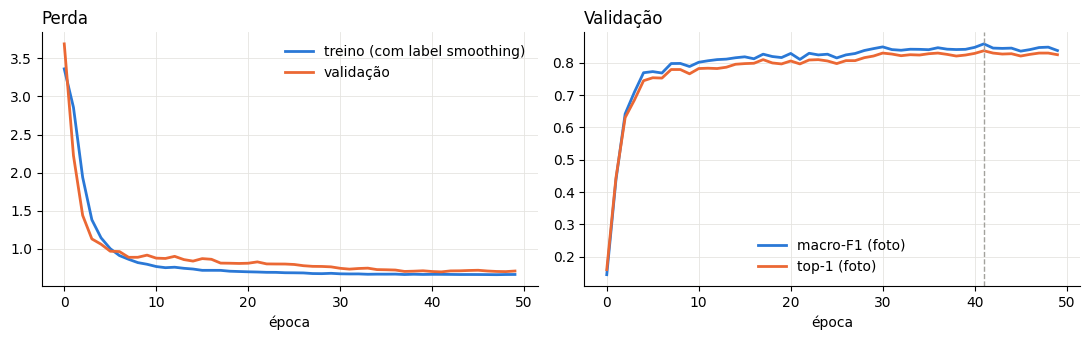

tempo médio por época: 38s


In [19]:
import matplotlib.pyplot as plt

seed = cfg["seeds"][0]
res_dir = drive_root / paths["drive_subdirs"]["results"] / exp / f"seed_{seed}"
h = pd.read_csv(res_dir / "history.csv")
blue, orange = "#2a78d6", "#eb6834"  # paleta categórica validada

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.5))
a1.plot(h["epoch"], h["train_loss"], color=blue, lw=2, label="treino (com label smoothing)")
a1.plot(h["epoch"], h["val_loss"], color=orange, lw=2, label="validação")
a1.set_title("Perda", loc="left")
a2.plot(h["epoch"], h["val_macro_f1"], color=blue, lw=2, label="macro-F1 (foto)")
a2.plot(h["epoch"], h["val_top1"], color=orange, lw=2, label="top-1 (foto)")
a2.axvline(results[seed]["best_epoch"], color="#a3a29d", lw=1, ls="--")
a2.set_title("Validação", loc="left")
for a in (a1, a2):
    a.set_xlabel("época")
    a.grid(color="#e5e4e0", lw=0.6)
    a.set_axisbelow(True)
    for side in ("top", "right"):
        a.spines[side].set_visible(False)
    a.legend(frameon=False)
plt.tight_layout()
plt.show()
print(f"tempo médio por época: {h['epoch_time_s'].mean():.0f}s")

F1 por classe no teste (por foto), da pior para a melhor:

In [20]:
species = pd.read_csv(manifest.parent / "species.csv").dropna(subset=["class_index"])
names = species.set_index(species["class_index"].astype(int))["scientific_name"]
pc = pd.read_csv(res_dir / "per_class_test.csv", index_col="class_index")
pc.insert(0, "especie", names)
pc.sort_values("f1").round(3)

,especie,precision,recall,f1,support
class_index,,,,,
21,Qualea parviflora,0.676,0.479,0.561,48
20,Qualea grandiflora,0.717,0.683,0.699,63
8,Eugenia dysenterica,0.707,0.744,0.725,39
6,Eriotheca pubescens,0.732,0.769,0.750,39
3,Caryocar brasiliense,0.691,0.855,0.764,55
4,Copaifera langsdorffii,0.867,0.684,0.765,19
12,Kielmeyera coriacea,0.791,0.756,0.773,45
25,Syagrus flexuosa,0.875,0.737,0.800,19
7,Erythrina speciosa,1.000,0.667,0.800,12
